In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
test_data = datasets.FashionMNIST(root="data",train=False, download=True, transform=ToTensor())
train_loader = DataLoader(train_data,batch_size=64, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data,batch_size=64,shuffle=True,num_workers=0)
print(len(train_data),len(test_data))

60000 10000


In [7]:
#layers optimization
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

model = Net()
print(model)

X, y = next(iter(train_loader))
print(model(X).shape)

Net(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
torch.Size([64, 10])


In [12]:
#Loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [13]:
#Training loop
epoch_losses= []
for epoch in range(5):
    model.train()
    running = 0.0
    for X, y in train_loader:
        pred=model(X)
        loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item()
    avg = running / len(train_loader)
    epoch_losses.append(avg)
    print(f"epoch {epoch+1}: loss {avg:4f}")

epoch 1: loss 0.628028
epoch 2: loss 0.435271
epoch 3: loss 0.393032
epoch 4: loss 0.368519
epoch 5: loss 0.349049


In [16]:
model.eval()
correct=0
with torch.no_grad():
    for X, y in test_loader:
        pred = model(X)
        correct += (pred.argmax(1) == y).sum().item()
print("test accuracy:" , correct / len(test_data))
print("random baseline:",1/10)

test accuracy: 0.8636
random baseline: 0.1


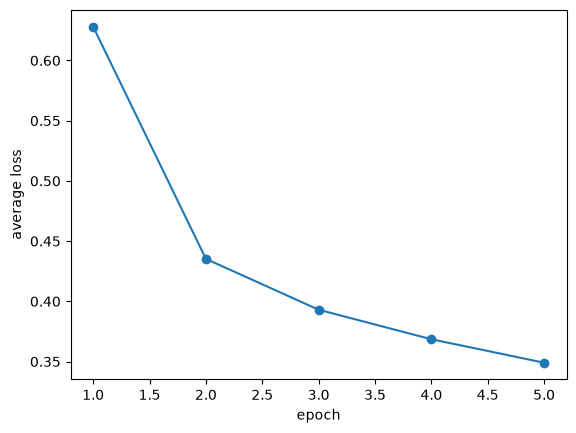

In [23]:
#Loss Curve
plt.plot(range(1, 6), epoch_losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("average loss")
plt.savefig("loss_curve.png")
plt.show()

In [26]:
#Per-class accuracy

labels_map = {0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
              5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"}
class_correct = [0]*10
class_total = [0]*10
model.eval()
with torch.no_grad():
    for X, y in test_loader:
        pred = model(X).argmax(1)
        for label, p in zip(y, pred):
            class_total[label] += 1
            class_correct[label] +=int(label == p)
for i in range(10):
    print(labels_map[i], class_correct[i] / class_total[i])

T-Shirt 0.799
Trouser 0.964
Pullover 0.793
Dress 0.86
Coat 0.757
Sandal 0.945
Shirt 0.689
Sneaker 0.964
Bag 0.972
Ankle Boot 0.893
